Abstract


* Question 1: Difference in Wheat Yield
• Null Hypothesis H0: There is no statistically significant difference in mean wheat yield between developed and developing countries.
• Alternative Hypothesis H1: There is a statistically significant difference in mean wheat yield between developed and developing countries.
* Question 2: Effect of Chemical Fertilizer Usage
• Null Hypothesis H0: Chemical fertilizer usage has no statistically significant effect on agricultural yield.
• Alternative Hypothesis H1: Chemical fertilizer usage has a statistically significant positive effect on agricultural yield.
* Question 3: Relationship Between Irrigated Land and Yield Stability
• Null Hypothesis H0: There is no statistically significant relationship between the size of irrigated agricultural land and yield stability.
• Alternative Hypothesis H1: There is a statistically significant relationship between the size of irrigated agricultural land and yield stability.

## Data merge

In [1]:
import pandas as pd

In [2]:
prod_file = 'Production_Crops_Livestock_E_All_Data_(Normalized).csv'
fert_file = 'Inputs_FertilizersNutrient_E_All_Data_(Normalized).csv'
land_file = 'Inputs_LandUse_E_All_Data_(Normalized).csv'

selected_countries = [
    'Ireland', 
    'United Kingdom of Great Britain and Northern Ireland', 
    'France', 
    'United States of America',
    'India', 
    'Mongolia']
selected_crops = ['Wheat', 'Barley', 'Potatoes']
start_year = 2000
use_cols = ['Area', 'Item', 'Element', 'Year', 'Value']

In [3]:
# (Production)
df_prod = pd.read_csv(prod_file, usecols=use_cols, encoding='latin1')
df_yield = df_prod[
    (df_prod['Area'].isin(selected_countries)) &
    (df_prod['Item'].isin(selected_crops)) &
    (df_prod['Element'] == 'Yield') &
    (df_prod['Year'] >= start_year)
][['Area', 'Item', 'Year', 'Value']].rename(columns={
    'Area': 'Country', 
    'Item': 'Crop_Type', 
    'Value': 'Yield_hg_ha'})

# (Fertilizers )
df_fert = pd.read_csv(fert_file, usecols=use_cols, encoding='latin1')
df_fert_clean = df_fert[
    (df_fert['Area'].isin(selected_countries)) &
    (df_fert['Item'] == 'Nutrient nitrogen N (total)') &
    (df_fert['Element'] == 'Agricultural Use') &
    (df_fert['Year'] >= start_year)
][['Area', 'Year', 'Value']].rename(columns={
    'Area': 'Country', 
    'Value': 'Nitrogen_Fertilizer_tonnes'})

# (Land Use )
df_land = pd.read_csv(land_file, usecols=use_cols, encoding='latin1')
df_land_clean = df_land[
    (df_land['Area'].isin(selected_countries)) &
    (df_land['Item'] == 'Cropland') &
    (df_land['Element'] == 'Area') &
    (df_land['Year'] >= start_year)
][['Area', 'Year', 'Value']].rename(columns={
    'Area': 'Country', 
    'Value': 'Cropland_1000ha'})

In [4]:
# INNER JOIN (MERGE)
df_merged = pd.merge(df_yield, df_fert_clean, on=['Country', 'Year'], how='inner')
df_final = pd.merge(df_merged, df_land_clean, on=['Country', 'Year'], how='inner')

In [5]:
df_final.to_csv('final_crop_data.csv', index=False)

print(f"\Merged! Total rows: {len(df_final)}")
print("Countries:", df_final['Country'].unique())
display(df_final.head(10))


\Merged! Total rows: 450
Countries: <ArrowStringArray>
[                                              'France',
                                                'India',
                                              'Ireland',
                                             'Mongolia',
 'United Kingdom of Great Britain and Northern Ireland',
                             'United States of America']
Length: 6, dtype: str


,Country,Crop_Type,Year,Yield_hg_ha,Nitrogen_Fertilizer_tonnes,Cropland_1000ha
0,France,Barley,2000,6330.0,2316300.0,19495.1
1,France,Barley,2001,5747.2,2397000.0,19480.6
2,France,Barley,2002,6687.6,2203200.0,19499.8
3,France,Barley,2003,5599.5,2375400.0,19470.8
4,France,Barley,2004,6765.7,2324000.0,19478.8
5,France,Barley,2005,6436.2,2205000.0,19488.2
6,France,Barley,2006,6237.9,2204665.0,19435.6
7,France,Barley,2007,5577.0,2402000.0,19358.3
8,France,Barley,2008,6764.4,2099000.0,19320.0
9,France,Barley,2009,6836.3,1900820.0,19283.4


## 1.Charactureisation of the dataset

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

In [7]:
df_final.to_csv('final_crop_data.csv')

In [8]:
df_final['Country'] = df_final['Country'].replace({
    'United Kingdom of Great Britain and Northern Ireland': 'UK',
    'United States of America': 'USA'})
df_final = df_final.dropna().reset_index(drop=True)

In [9]:
print("Rows and Columns (shape):", df_final.shape)

Rows and Columns (shape): (450, 6)


In [10]:
df_final.head(5)

,Country,Crop_Type,Year,Yield_hg_ha,Nitrogen_Fertilizer_tonnes,Cropland_1000ha
0,France,Barley,2000,6330.0,2316300.0,19495.1
1,France,Barley,2001,5747.2,2397000.0,19480.6
2,France,Barley,2002,6687.6,2203200.0,19499.8
3,France,Barley,2003,5599.5,2375400.0,19470.8
4,France,Barley,2004,6765.7,2324000.0,19478.8


In [11]:
df_final.tail(5)

,Country,Crop_Type,Year,Yield_hg_ha,Nitrogen_Fertilizer_tonnes,Cropland_1000ha
445,USA,Wheat,2020,3341.7,11925954.0,157015.2000
446,USA,Wheat,2021,2980.5,11722823.0,155874.6600
447,USA,Wheat,2022,3126.5,11426152.0,154734.1251
448,USA,Wheat,2023,3269.4,11426152.0,154734.1300
449,USA,Wheat,2024,3446.2,11426152.0,154734.1300


In [12]:
df_final.info() 

<class 'pandas.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Country                     450 non-null    str    
 1   Crop_Type                   450 non-null    str    
 2   Year                        450 non-null    int64  
 3   Yield_hg_ha                 450 non-null    float64
 4   Nitrogen_Fertilizer_tonnes  450 non-null    float64
 5   Cropland_1000ha             450 non-null    float64
dtypes: float64(3), int64(1), str(2)
memory usage: 26.3 KB


In [13]:
df_final.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,450.0,2.012000e+03,7.219128e+00,2000.0,2006.0,2.012000e+03,2.018000e+03,2024.0
Yield_hg_ha,450.0,1.418987e+04,1.547124e+04,381.5,3183.1,6.992700e+03,2.144192e+04,51636.5
Nitrogen_Fertilizer_tonnes,450.0,5.181094e+06,6.408222e+06,0.0,345154.0,1.465310e+06,1.142615e+07,22147900.0
Cropland_1000ha,450.0,5.980203e+04,7.550310e+04,434.0,1179.6,1.210407e+04,1.598910e+05,178100.0


## 2.Duplicates and Missing values

In [14]:
df_final.duplicated().sum()

np.int64(0)

In [15]:
df_final.isnull().sum()

Country                       0
Crop_Type                     0
Year                          0
Yield_hg_ha                   0
Nitrogen_Fertilizer_tonnes    0
Cropland_1000ha               0
dtype: int64

In [16]:
sns.set_theme(style="whitegrid", palette="Set2")

# 2.1 IQR 

In [32]:
def calc_iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

In [33]:
overall_stats = pd.DataFrame({
    'Count': [df_final['Yield_hg_ha'].count()],
    'Mean': [df_final['Yield_hg_ha'].mean()],
    'SD': [df_final['Yield_hg_ha'].std()],
    'Median': [df_final['Yield_hg_ha'].median()],
    'IQR': [df_final['Yield_hg_ha'].quantile(0.75) - df_final['Yield_hg_ha'].quantile(0.25)],
    'Skewness': [df_final['Yield_hg_ha'].skew()]
}).round(2)

print("Overall Crop Yield Summary Statistics")
display(overall_stats)

Overall Crop Yield Summary Statistics


,Count,Mean,SD,Median,IQR,Skewness
0,450,14189.87,15471.24,6992.7,18258.82,1.17


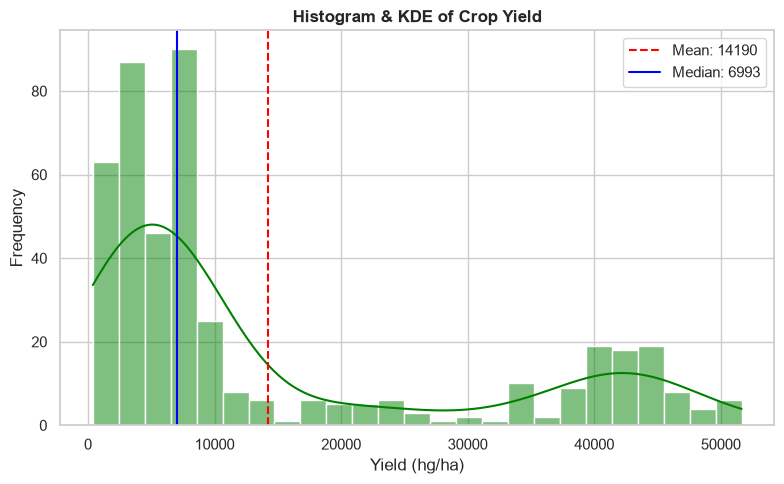

In [34]:
plt.figure(figsize=(8, 5))

sns.histplot(df_final['Yield_hg_ha'], kde=True, bins=25, color='green')
plt.axvline(df_final['Yield_hg_ha'].mean(), color='red', linestyle='--', label=f"Mean: {df_final['Yield_hg_ha'].mean():.0f}")
plt.axvline(df_final['Yield_hg_ha'].median(), color='blue', linestyle='-', label=f"Median: {df_final['Yield_hg_ha'].median():.0f}")

plt.title('Histogram & KDE of Crop Yield', fontweight='bold')
plt.xlabel('Yield (hg/ha)')
plt.ylabel('Frequency')
plt.legend()

plt.tight_layout()
plt.show()

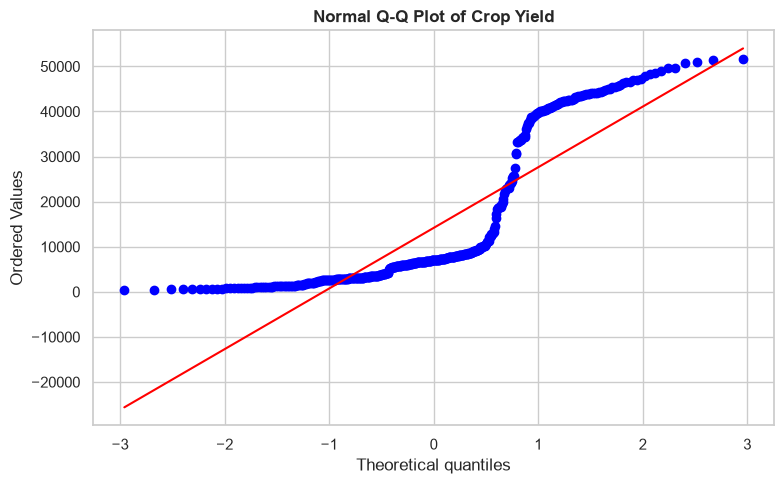

In [35]:
plt.figure(figsize=(8, 5))

stats.probplot(df_final['Yield_hg_ha'], dist="norm", plot=plt)

plt.title('Normal Q-Q Plot of Crop Yield', fontweight='bold')
plt.tight_layout()
plt.show()

In [36]:
country_stats = df_final.groupby('Country')['Yield_hg_ha'].agg(
    Count='count',
    Mean='mean',
    SD='std',
    Median='median',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    Skewness='skew'
).round(2)

print("Crop Yield Summary Statistics by Country")
display(country_stats)

Crop Yield Summary Statistics by Country


,Count,Mean,SD,Median,IQR,Skewness
Country,,,,,,
France,75,18456.38,16942.91,7101.8,33786.40,0.74
India,75,8898.60,8926.71,3044.5,16168.90,0.81
Ireland,75,17618.68,13889.70,8998.3,25744.80,0.85
Mongolia,75,4271.01,4711.89,1336.9,8069.85,0.93
UK,75,18223.56,16241.68,7889.7,33322.45,0.75
USA,75,17671.01,20480.13,3742.9,40828.45,0.75


/var/folders/v6/v4q54r017v92tsdnk65qj8y00000gn/T/ipykernel_4816/2173354658.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_final, x='Country', y='Yield_hg_ha', palette="Set2")


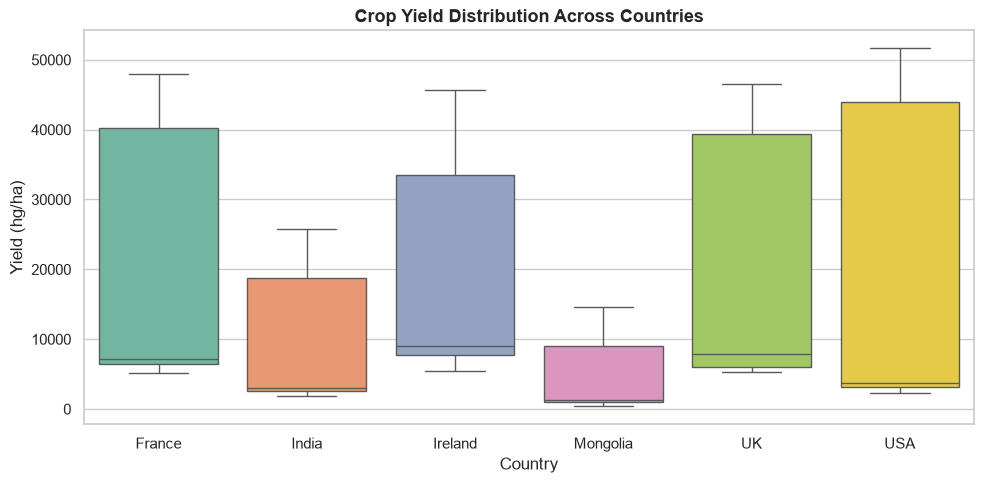

In [37]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_final, x='Country', y='Yield_hg_ha', palette="Set2")
plt.title('Crop Yield Distribution Across Countries', fontsize=13, fontweight='bold')
plt.xlabel('Country')
plt.ylabel('Yield (hg/ha)')
plt.tight_layout()
plt.show()

In [30]:
crop_stats = df_final.groupby('Crop_Type')['Yield_hg_ha'].agg(
    Count='count',
    Mean='mean',
    SD='std',
    Median='median',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    Skewness='skew'
).round(2)

print("Crop Yield Summary Statistics by Crop Type")
display(crop_stats)

Crop Yield Summary Statistics by Crop Type


,Count,Mean,SD,Median,IQR,Skewness
Crop_Type,,,,,,
Barley,150,4431.58,2272.06,4699.50,3910.98,-0.18
Potatoes,150,32960.42,13227.89,39177.95,21417.92,-0.63
Wheat,150,5177.62,2970.47,4424.30,5011.12,0.05


/var/folders/v6/v4q54r017v92tsdnk65qj8y00000gn/T/ipykernel_4816/1052085031.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_final, x='Crop_Type', y='Yield_hg_ha', palette="Set3")


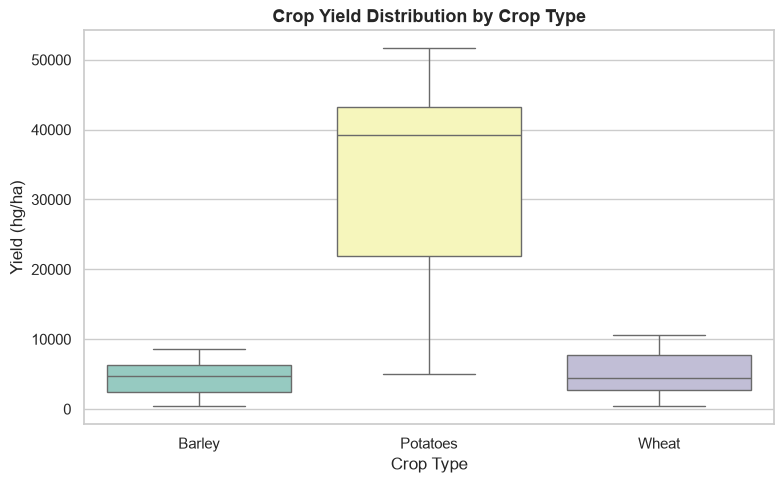

In [31]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_final, x='Crop_Type', y='Yield_hg_ha', palette="Set3")
plt.title('Crop Yield Distribution by Crop Type', fontsize=13, fontweight='bold')
plt.xlabel('Crop Type')
plt.ylabel('Yield (hg/ha)')
plt.tight_layout()
plt.show()

In [25]:
# 7. Chi-Square  for (Yield_Level)
median_yield = df_final['Yield_hg_ha'].median()
df_final['Yield_Level'] = df_final['Yield_hg_ha'].apply(lambda x: 'High' if x >= median_yield else 'Low')